# Lab 2: Word Representations (SOLUTION)
**Behind the Secrets of Large Language Models**, TU Dresden, WiSe 2026/27

| Chapter | Topic |
|---|---|
| A | Tokenization |
| B | Word embeddings |
| C | Applications |

Works in Google Colab (CPU is enough) or locally. Run the setup cell first. Cells marked `# TODO` are for you, bonus exercises (★) are optional.

In [1]:
%pip install -q gensim tokenizers transformers datasets

import re
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import gensim.downloader as api

# A. Tokenization

What do we actually embed: words, characters or subwords? (see slides 60-74)

| Part | Topic |
|---|---|
| A1 | Words or characters? |
| A2 | BPE by hand |
| A3 | Training a BPE tokenizer |
| A4 | The GPT-2 tokenizer |

## A1. Words or characters?

In [2]:
text = "Mr. O'Neill thinks that the boys' stories about San Francisco aren't amusing."

**Exercise A1.1.** Split `text` into characters, on whitespace (`text.split()`) and with `re.findall(r"\w+|[^\w\s]", text)`. Print the number of tokens and of distinct tokens.

*Goal:* see what each method does with *Mr.*, *O'Neill*, *aren't*, *San Francisco* (see slide 61).

In [3]:
def report(name, tokens):
    print(f"{name}: {len(tokens)} tokens, {len(set(tokens))} distinct")
    print(tokens, "\n")

char_tokens = list(text)
space_tokens = text.split()
regex_tokens = re.findall(r"\w+|[^\w\s]", text)

report("characters", char_tokens)
report("whitespace", space_tokens)
report("regex", regex_tokens)

characters: 77 tokens, 25 distinct
['M', 'r', '.', ' ', 'O', "'", 'N', 'e', 'i', 'l', 'l', ' ', 't', 'h', 'i', 'n', 'k', 's', ' ', 't', 'h', 'a', 't', ' ', 't', 'h', 'e', ' ', 'b', 'o', 'y', 's', "'", ' ', 's', 't', 'o', 'r', 'i', 'e', 's', ' ', 'a', 'b', 'o', 'u', 't', ' ', 'S', 'a', 'n', ' ', 'F', 'r', 'a', 'n', 'c', 'i', 's', 'c', 'o', ' ', 'a', 'r', 'e', 'n', "'", 't', ' ', 'a', 'm', 'u', 's', 'i', 'n', 'g', '.'] 

whitespace: 12 tokens, 12 distinct
['Mr.', "O'Neill", 'thinks', 'that', 'the', "boys'", 'stories', 'about', 'San', 'Francisco', "aren't", 'amusing.'] 

regex: 19 tokens, 16 distinct
['Mr', '.', 'O', "'", 'Neill', 'thinks', 'that', 'the', 'boys', "'", 'stories', 'about', 'San', 'Francisco', 'aren', "'", 't', 'amusing', '.'] 



**Exercise A1.2.** Build a vocabulary from `train_text` (lowercased) and list the words of `test_text` that are not in it.

*Goal:* see why word-level models need `<UNK>` and why *open / opened / reopened* as separate words is wasteful (see slides 62-63).

In [4]:
train_text = '''The students opened their books. The teacher opens the window.
Students in Dresden read books about language models. The model reads the text.'''
test_text = "The students reopened the windows and were reading about tokenizers."

def words(s):
    return re.findall(r"\w+|[^\w\s]", s.lower())

vocab = set(words(train_text))
oov = [w for w in words(test_text) if w not in vocab]
print("vocabulary size:", len(vocab))
print("OOV:", oov)

vocabulary size: 18
OOV: ['reopened', 'windows', 'and', 'were', 'reading', 'tokenizers']


## A2. Byte pair encoding by hand

The toy corpus from the lecture (see slides 66-70).

In [5]:
word_freqs = {"hug": 10, "pug": 5, "pun": 12, "bun": 4, "hugs": 5}
splits = {w: list(w) for w in word_freqs}
base_vocab = sorted({c for w in word_freqs for c in w})
print("Base vocabulary:", base_vocab)
print(splits)

Base vocabulary: ['b', 'g', 'h', 'n', 'p', 's', 'u']
{'hug': ['h', 'u', 'g'], 'pug': ['p', 'u', 'g'], 'pun': ['p', 'u', 'n'], 'bun': ['b', 'u', 'n'], 'hugs': ['h', 'u', 'g', 's']}


**Exercise A2.1.** Write `pair_counts(splits)`: count all pairs of neighbouring symbols, weighted by word frequency.

*Goal:* reproduce the table on slide 67 (top pair `('u', 'g')` with 20).

In [6]:
def pair_counts(splits):
    counts = Counter()
    for w, symbols in splits.items():
        for a, b in zip(symbols, symbols[1:]):
            counts[(a, b)] += word_freqs[w]
    return counts

print(pair_counts(splits).most_common(5))

[(('u', 'g'), 20), (('p', 'u'), 17), (('u', 'n'), 16), (('h', 'u'), 15), (('g', 's'), 5)]


**Exercise A2.2.** Write `merge(pair, splits)`, then run 3 merges: take the most frequent pair, merge it, append it to `merges` and the new symbol to `vocab_bpe`.

*Goal:* get the merges *ug*, *un*, *hug* (see slides 68-70).

In [7]:
def merge(pair, splits):
    a, b = pair
    new_splits = {}
    for w, symbols in splits.items():
        out, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == a and symbols[i + 1] == b:
                out.append(a + b)
                i += 2
            else:
                out.append(symbols[i])
                i += 1
        new_splits[w] = out
    return new_splits

merges = []
vocab_bpe = list(base_vocab)
current = dict(splits)
for step in range(3):
    best = pair_counts(current).most_common(1)[0][0]
    current = merge(best, current)
    merges.append(best)
    vocab_bpe.append(best[0] + best[1])
    print(f"step {step + 1}: merge {best} ->", current)
print("Final vocabulary:", vocab_bpe)

step 1: merge ('u', 'g') -> {'hug': ['h', 'ug'], 'pug': ['p', 'ug'], 'pun': ['p', 'u', 'n'], 'bun': ['b', 'u', 'n'], 'hugs': ['h', 'ug', 's']}
step 2: merge ('u', 'n') -> {'hug': ['h', 'ug'], 'pug': ['p', 'ug'], 'pun': ['p', 'un'], 'bun': ['b', 'un'], 'hugs': ['h', 'ug', 's']}
step 3: merge ('h', 'ug') -> {'hug': ['hug'], 'pug': ['p', 'ug'], 'pun': ['p', 'un'], 'bun': ['b', 'un'], 'hugs': ['hug', 's']}
Final vocabulary: ['b', 'g', 'h', 'n', 'p', 's', 'u', 'ug', 'un', 'hug']


**Exercise A2.3.** Write `bpe_tokenize(word)`: start from the characters and apply `merges` in the order they were learned. Try *hugs*, *bugs*, *pugs*, *mug*.

*Goal:* see how BPE handles unseen words, and what goes wrong with *m* (see slide 71).

In [8]:
def bpe_tokenize(word):
    symbols = list(word)
    for pair in merges:
        symbols = merge(pair, {word: symbols})[word]
    return symbols

for w in ["hugs", "bugs", "pugs", "mug"]:
    print(w, bpe_tokenize(w))

hugs ['hug', 's']
bugs ['b', 'ug', 's']
pugs ['p', 'ug', 's']
mug ['m', 'ug']


## A3. Training a BPE tokenizer on real data

8,530 movie reviews from the Rotten Tomatoes dataset (used again in chapter C).

In [9]:
from datasets import load_dataset
from tokenizers import ByteLevelBPETokenizer

reviews = load_dataset("cornell-movie-review-data/rotten_tomatoes")["train"]["text"]
print(len(reviews), "reviews, e.g.:", reviews[0])

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

8530 reviews, e.g.: the rock is destined to be the 21st century's new " conan " and that he's going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .


**Exercise A3.1.** Train a `ByteLevelBPETokenizer` with `vocab_size` 300, 1000 and 5000 (`min_frequency=2`). For each, print the average number of tokens per word on the first 500 reviews and the tokens of `sample`.

*Goal:* see the trade-off between vocabulary size and sequence length (see slides 64 and 71).

In [10]:
sample = "The tokenization of unbelievable movies"
for size in [300, 1000, 5000]:
    tok = ByteLevelBPETokenizer()
    tok.train_from_iterator(reviews, vocab_size=size, min_frequency=2, show_progress=False)
    n_tokens = sum(len(tok.encode(r).ids) for r in reviews[:500])
    n_words = sum(len(r.split()) for r in reviews[:500])
    print(f"vocab {size:5d}: {n_tokens / n_words:.2f} tokens per word", tok.encode(sample).tokens)

vocab   300: 3.65 tokens per word ['T', 'he', 'Ġto', 'k', 'en', 'i', 'z', 'at', 'i', 'on', 'Ġof', 'Ġ', 'u', 'n', 'b', 'e', 'l', 'i', 'e', 'v', 'a', 'b', 'l', 'e', 'Ġm', 'o', 'v', 'i', 'es']
vocab  1000: 1.96 tokens per word ['T', 'he', 'Ġto', 'k', 'en', 'iz', 'ation', 'Ġof', 'Ġun', 'b', 'el', 'ie', 'v', 'able', 'Ġmovies']
vocab  5000: 1.34 tokens per word ['T', 'he', 'Ġto', 'ken', 'ization', 'Ġof', 'Ġun', 'belie', 'vable', 'Ġmovies']


## A4. The tokenizer of a real LLM

GPT-2 uses byte-level BPE with a vocabulary of 50,257 tokens.

In [11]:
from transformers import AutoTokenizer
gpt2 = AutoTokenizer.from_pretrained("gpt2")
print(gpt2.vocab_size)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

50257


**Exercise A4.1.** Run `gpt2.tokenize(...)` on *tokenization*, *unbelievable*, *Dresden*, *" Dresden"* (leading space), *ChatGPT*, *2026*, *Donaudampfschifffahrtsgesellschaft*.

*Goal:* see how a real tokenizer splits words, spaces and numbers.

In [12]:
for w in ["tokenization", "unbelievable", "Dresden", " Dresden", "ChatGPT", "2026",
          "Donaudampfschifffahrtsgesellschaft"]:
    print(repr(w), gpt2.tokenize(w))

'tokenization' ['token', 'ization']
'unbelievable' ['un', 'bel', 'iev', 'able']
'Dresden' ['D', 'res', 'den']
' Dresden' ['ĠDresden']
'ChatGPT' ['Chat', 'G', 'PT']
'2026' ['20', '26']
'Donaudampfschifffahrtsgesellschaft' ['Don', 'aud', 'amp', 'fs', 'ch', 'if', 'ff', 'ah', 'r', 'ts', 'ges', 'ells', 'cha', 'ft']


**Exercise A4.2.** Count the GPT-2 tokens of each sentence and divide by the English count. Add a language you speak.

*Goal:* see the token premium of languages other than English (see slides 72-73). Then compare other tokenizers at https://tiktokenizer.vercel.app/, also on a few lines of Python code: how are spaces and indentation handled?

In [13]:
sentences = {
    "English": "The weather in Dresden is nice today, so we are going for a walk along the river.",
    "German":  "Das Wetter in Dresden ist heute schön, deshalb gehen wir am Fluss spazieren.",
    "Spanish": "Hoy hace buen tiempo en Dresde, así que vamos a pasear junto al río.",
    "Hindi":   "आज ड्रेसडेन में मौसम अच्छा है, इसलिए हम नदी के किनारे टहलने जा रहे हैं।",
    "Chinese": "今天德累斯顿天气很好，所以我们去河边散步。",
}
n_en = len(gpt2.encode(sentences["English"]))
for lang, s in sentences.items():
    n = len(gpt2.encode(s))
    print(f"{lang:8s} {len(s):3d} characters  {n:3d} tokens  x{n / n_en:.1f}")

English   81 characters   19 tokens  x1.0
German    76 characters   28 tokens  x1.5
Spanish   68 characters   29 tokens  x1.5
Hindi     71 characters  110 tokens  x5.8
Chinese   21 characters   44 tokens  x2.3


**Exercise A4.3.** For each string below, print the number of characters (`len`), the Unicode code points (`ord`), the number of UTF-8 bytes (`s.encode("utf-8")`) and the GPT-2 tokens. Then decode the tokens of 👋🏼 one by one with `gpt2.decode([i])`.

*Goal:* see why GPT-2 builds its vocabulary on bytes, and that a token does not have to be a whole character (see slide 71).

In [14]:
strings = ["a", "ß", "€", "🫨", "👋🏼", "hi there 👋🏼"]
for s in strings:
    b = s.encode("utf-8")
    print(f"{s!r:16} chars={len(s):2d}  code points={[ord(c) for c in s]}  bytes={len(b):2d}  tokens={gpt2.tokenize(s)}")

print([gpt2.decode([i]) for i in gpt2.encode("👋🏼")])

'a'              chars= 1  code points=[97]  bytes= 1  tokens=['a']
'ß'              chars= 1  code points=[223]  bytes= 2  tokens=['ÃŁ']
'€'              chars= 1  code points=[8364]  bytes= 3  tokens=['âĤ¬']
'🫨'              chars= 1  code points=[129768]  bytes= 4  tokens=['ðŁ', '«', '¨']
'👋🏼'             chars= 2  code points=[128075, 127996]  bytes= 8  tokens=['ðŁĳ', 'ĭ', 'ðŁ', 'ı', '¼']
'hi there 👋🏼'    chars=11  code points=[104, 105, 32, 116, 104, 101, 114, 101, 32, 128075, 127996]  bytes=17  tokens=['hi', 'Ġthere', 'ĠðŁĳ', 'ĭ', 'ðŁ', 'ı', '¼']
['�', '�', '�', '�', '�']


**Exercise A4.4.** *"How many r are in strawberry?"* is a famous question that LLMs used to get wrong. Tokenize the question and the words *strawberry* and *" strawberry"*.

*Goal:* see what the model actually receives when it is asked to count letters.

In [15]:
question = "How many r are in strawberry?"
print(gpt2.tokenize(question))
print(gpt2.tokenize("strawberry"), gpt2.tokenize(" strawberry"))
print("letters r:", "strawberry".count("r"))

['How', 'Ġmany', 'Ġr', 'Ġare', 'Ġin', 'Ġstrawberry', '?']
['st', 'raw', 'berry'] ['Ġstrawberry']
letters r: 3


## A★ Bonus (optional): your own BPE on real data

**Exercise.** Apply your `pair_counts`, `merge` and `bpe_tokenize` from A2 to the word frequencies of the first 2000 reviews (`Counter` over `review.split()`). Learn 300 merges, print the first 25 learned subwords and the compression ratio (characters / tokens over all words, weighted by frequency), and tokenize *unbelievable*, *movies*, *boring*, *tokenization*, *dresden*.

*Goal:* see which subwords BPE learns first on real text.

Hint: `pair_counts` reads the global `word_freqs`, so just assign a new one.

In [16]:
word_freqs = Counter(w for r in reviews[:2000] for w in r.split())
current = {w: list(w) for w in word_freqs}
merges = []
for _ in range(300):
    best = pair_counts(current).most_common(1)[0][0]
    current = merge(best, current)
    merges.append(best)

print([a + b for a, b in merges[:25]])
n_chars = sum(len(w) * f for w, f in word_freqs.items())
n_tokens = sum(len(current[w]) * f for w, f in word_freqs.items())
print(f"compression ratio: {n_chars / n_tokens:.2f}x")
for w in ["unbelievable", "movies", "boring", "tokenization", "dresden"]:
    print(w, bpe_tokenize(w))

['th', 'in', 'an', 'er', 'the', 're', 'en', 'is', 'at', 'es', 'on', 'it', 'ing', 'or', 'and', 'al', 'ou', 'of', 'ar', 'st', 'il', 'ed', 'to', 'ly', 'ic']
compression ratio: 2.05x
unbelievable ['un', 'b', 'el', 'i', 'ev', 'able']
movies ['movi', 'es']
boring ['b', 'or', 'ing']
tokenization ['to', 'k', 'en', 'iz', 'ation']
dresden ['d', 're', 's', 'd', 'en']


# B. Word Embeddings

*"You shall know a word by the company it keeps"* (Firth, 1957). From count vectors to word2vec and pretrained GloVe (see slides 16-58).

| Part | Topic |
|---|---|
| B1 | Vectors, cosine and tf-idf |
| B2 | Training word2vec |
| B3 | Embedding magic: analogies and bias |

## B1. Vectors, cosine and tf-idf

**Exercise B1.1.** Write `cosine(u, v)`. Then compute the dot product and the cosine of `V1` with every other vector, for both sets.

*Goal:* see why similarity is measured with cosine, not the dot product (see slides 23-27).

In [17]:
def cosine(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

set_a = {
    "V1": [1, 1, 1, 1, 0, 0, 0, 0],
    "V2": [1, 1, 1, 1, 0, 0, 0, 0],
    "V3": [1, 1, 0, 0, 0, 0, 1, 1],
    "V4": [1, 0, 0, 0, 0, 1, 1, 1],
    "V5": [0, 0, 0, 0, 1, 1, 1, 1],
}
set_b = {"V1": [3, 4], "V2": [3, 4], "V3": [4, 3], "V4": [0, 4], "V5": [0, 3]}

for vectors in [set_a, set_b]:
    v1 = np.array(vectors["V1"])
    for name, v in vectors.items():
        v = np.array(v)
        print(f"V1 vs {name}: dot = {v1 @ v:2d}, cosine = {cosine(v1, v):.2f}")
    print()

V1 vs V1: dot =  4, cosine = 1.00
V1 vs V2: dot =  4, cosine = 1.00
V1 vs V3: dot =  2, cosine = 0.50
V1 vs V4: dot =  1, cosine = 0.25
V1 vs V5: dot =  0, cosine = 0.00

V1 vs V1: dot = 25, cosine = 1.00
V1 vs V2: dot = 25, cosine = 1.00
V1 vs V3: dot = 24, cosine = 0.96
V1 vs V4: dot = 16, cosine = 0.80
V1 vs V5: dot = 12, cosine = 0.80



**Exercise B1.2.** Term-document matrix of four Shakespeare plays (see slides 17-20).
1. Compute the cosine between all pairs of plays.
2. Repeat without the row *good*.
3. Compute $\text{idf} = \log_{10}(N / \text{df})$ over all $N = 37$ plays (`df` below) and the tf-idf matrix with $\text{tf} = \log_{10}(\text{count} + 1)$.

*Goal:* see how a word that occurs everywhere hides the difference between comedies and histories, and how tf-idf removes it (see slides 29-33).

In [18]:
plays = ["As You Like It", "Twelfth Night", "Julius Caesar", "Henry V"]
words = ["battle", "good", "fool", "wit"]
counts = np.array([
    [  1,  0,  7, 13],
    [114, 80, 62, 89],
    [ 36, 58,  1,  4],
    [ 20, 15,  2,  3],
])
N = 37
df = np.array([21, 37, 36, 34])  # in how many of the 37 plays each word occurs

def play_similarities(M):
    for i in range(4):
        for j in range(i + 1, 4):
            print(f"  {plays[i]:15s} ~ {plays[j]:15s} {cosine(M[:, i], M[:, j]):.2f}")

print("All words:")
play_similarities(counts)
print("Without 'good':")
play_similarities(counts[[0, 2, 3]])

idf = np.log10(N / df)
tfidf = np.log10(counts + 1) * idf[:, None]
print("idf:", {w: round(float(v), 3) for w, v in zip(words, idf)})
print(np.round(tfidf, 3))

All words:
  As You Like It  ~ Twelfth Night   0.95
  As You Like It  ~ Julius Caesar   0.94
  As You Like It  ~ Henry V         0.95
  Twelfth Night   ~ Julius Caesar   0.81
  Twelfth Night   ~ Henry V         0.82
  Julius Caesar   ~ Henry V         1.00
Without 'good':
  As You Like It  ~ Twelfth Night   0.97
  As You Like It  ~ Julius Caesar   0.27
  As You Like It  ~ Henry V         0.38
  Twelfth Night   ~ Julius Caesar   0.20
  Twelfth Night   ~ Henry V         0.33
  Julius Caesar   ~ Henry V         0.99
idf: {'battle': 0.246, 'good': 0.0, 'fool': 0.012, 'wit': 0.037}
[[0.074 0.    0.222 0.282]
 [0.    0.    0.    0.   ]
 [0.019 0.021 0.004 0.008]
 [0.049 0.044 0.018 0.022]]


## B2. Training word2vec

Skip-gram with negative sampling (see slides 39-51), trained on **text8**: Wikipedia, lowercased, no punctuation. We use the first 5 million tokens.

In [19]:
from gensim.models import Word2Vec
from gensim.models.word2vec import Text8Corpus

# api.load("text8") breaks with recent versions of smart_open, so we load the file path instead
sentences = list(Text8Corpus(api.load("text8", return_path=True)))[:500]

[==================================================] 100.0% 31.6/31.6MB downloaded


**Exercise B2.1.** Print the number of tokens, the vocabulary size and the 10 most frequent words of `sentences`.

*Goal:* know what the model is trained on.

In [20]:
tokens = [w for sent in sentences for w in sent]
freq = Counter(tokens)
print("tokens:", len(tokens))
print("vocabulary:", len(freq))
print(freq.most_common(10))

tokens: 5000000
vocabulary: 125354
[('the', 320177), ('of', 179026), ('and', 125769), ('one', 114853), ('in', 110762), ('a', 96176), ('to', 93548), ('zero', 76467), ('nine', 66546), ('two', 56502)]


**Exercise B2.2.** Train `Word2Vec` with `sg=1`, `negative=5`, `window=5`, `vector_size=100`, `min_count=5`. Print the shapes of `model.wv.vectors` and `model.syn1neg`.

*Goal:* find the target matrix **W** and the context matrix **C** (see slide 50).

In [21]:
model = Word2Vec(sentences=sentences, vector_size=100, window=5, min_count=5,
                 sg=1, negative=5, workers=2, seed=42)
print("W:", model.wv.vectors.shape, " C:", model.syn1neg.shape)

W: (36280, 100)  C: (36280, 100)


**Exercise B2.3.** Use `model.wv.most_similar` for *car*, *computer*, *germany*, *dresden*, and `model.wv.similarity` for *football / basketball* vs *football / bottle*. Then try *apricot*.

*Goal:* check that the neighbours make sense, and meet the OOV problem again.

In [22]:
for w in ["car", "computer", "germany", "dresden"]:
    print(w, [x for x, _ in model.wv.most_similar(w, topn=6)])

print(model.wv.similarity("football", "basketball"), model.wv.similarity("football", "bottle"))

try:
    model.wv["apricot"]
except KeyError as e:
    print("KeyError:", e)

car ['driver', 'cars', 'automobile', 'racing', 'airplane', 'motorcycle']
computer ['computers', 'hardware', 'computing', 'microcomputer', 'programmer', 'graphical']
germany ['italy', 'munich', 'switzerland', 'russia', 'austria', 'france']
dresden ['torgau', 'regensburg', 'freiburg', 'margraves', 'halle', 'lith']
0.8557038 0.116606206
KeyError: "Key 'apricot' not present"


**Exercise B2.4.** Try *king - man + woman* and *paris - france + germany* with `model.wv.most_similar(positive=[...], negative=[...])`.

*Goal:* see which analogies a model trained on 5M tokens can solve (see slide 54).

In [23]:
print(model.wv.most_similar(positive=["king", "woman"], negative=["man"], topn=5))
print(model.wv.most_similar(positive=["paris", "germany"], negative=["france"], topn=5))

[('throne', 0.6384121775627136), ('amalric', 0.6256036162376404), ('hezekiah', 0.6121895909309387), ('vii', 0.6117284893989563), ('jerusalem', 0.6086629629135132)]
[('munich', 0.7248367667198181), ('berlin', 0.7166324257850647), ('vienna', 0.6584069728851318), ('dresden', 0.6327552199363708), ('moscow', 0.628993034362793)]


**Exercise B2.5 (optional).** Retrain on `sentences[:200]` with a different `window` (2 vs 10), `vector_size` or `sg=0` (CBOW) and compare the neighbours of a few words.

*Goal:* get a feeling for the hyperparameters.

In [24]:
# TODO (optional)

## B3. Embedding magic with pretrained GloVe

50-dimensional vectors for 400,000 words, trained on 6 billion tokens.

In [25]:
glove = api.load("glove-wiki-gigaword-50")
print(glove["dresden"][:10])

[==================================================] 100.0% 66.0/66.0MB downloaded
[ 0.8944    0.03095  -0.13201  -0.94516  -0.5479   -0.069025  0.26644
  0.69794  -1.6257   -0.2765  ]


**Exercise B3.1.** Use `glove.most_similar` for *bank*, *apple*, *python*, *mouse*.

*Goal:* see that a static embedding mixes all senses of a word (see slide 7).

In [26]:
for w in ["bank", "apple", "python", "mouse"]:
    print(w, [x for x, _ in glove.most_similar(w, topn=8)])

bank ['banks', 'securities', 'banking', 'investment', 'exchange', 'financial', 'credit', 'lender']
apple ['blackberry', 'chips', 'iphone', 'microsoft', 'ipad', 'pc', 'ipod', 'intel']
python ['reticulated', 'spamalot', 'php', 'owl', 'mouse', 'reticulatus', 'perl', 'monkey']
mouse ['monkey', 'bugs', 'cat', 'rabbit', 'worm', 'clone', 'robot', 'spider']


**Exercise B3.2.** Implement `analogy(a, b, c)`: the word closest to `b - a + c`, excluding `a`, `b`, `c` (use `glove.similar_by_vector`). Test the cases below, then find two analogies that fail.

*Goal:* reproduce the parallelogram method (see slides 53-54).

In [27]:
def analogy(a, b, c, topn=1):
    target = glove[b] - glove[a] + glove[c]
    candidates = glove.similar_by_vector(target, topn=topn + 3)
    return [w for w, _ in candidates if w not in {a, b, c}][:topn]

tests = [("apple", "tree", "grape"), ("man", "king", "woman"), ("france", "paris", "italy"),
         ("walk", "walked", "swim"), ("good", "better", "bad")]
for t in tests:
    print(t, analogy(*t, topn=3))

for t in [("big", "biggest", "small"), ("hand", "glove", "foot"), ("sheep", "lamb", "cow")]:
    print(t, analogy(*t, topn=3))

('apple', 'tree', 'grape') ['vine', 'vines', 'trees']
('man', 'king', 'woman') ['queen', 'daughter', 'prince']
('france', 'paris', 'italy') ['rome', 'milan', 'turin']
('walk', 'walked', 'swim') ['swam', 'raced', 'rowed']
('good', 'better', 'bad') ['worse', 'too', 'unfortunately']
('big', 'biggest', 'small') ['largest', 'large', 'main']
('hand', 'glove', 'foot') ['50,000-square', '20-foot', 'infield']
('sheep', 'lamb', 'cow') ['chicken', 'beef', 'pork']


**Exercise B3.3.** Run *father : doctor :: mother : ?*. Then compute the cosine of each profession with the gender direction `g = glove["he"] - glove["she"]` (normalised) and sort.

*Goal:* see that embeddings copy stereotypes from their training data (see slide 57).

In [28]:
professions = ["nurse", "engineer", "doctor", "teacher", "programmer", "secretary", "pilot",
               "dancer", "scientist", "receptionist", "manager", "librarian", "surgeon", "housekeeper"]
print(analogy("father", "doctor", "mother", topn=3))

g = glove["he"] - glove["she"]
g /= np.linalg.norm(g)
scores = sorted((cosine(glove[p], g), p) for p in professions)
for s, p in scores:
    print(f"{p:13s} {s:+.3f}")

['nurse', 'pregnant', 'child']
nurse         -0.381
housekeeper   -0.373
receptionist  -0.370
dancer        -0.357
doctor        -0.124
librarian     -0.109
teacher       -0.104
surgeon       -0.053
pilot         -0.039
programmer    +0.033
scientist     +0.039
engineer      +0.125
secretary     +0.216
manager       +0.302


**Exercise B3.4.** Plot the words below in 2D with PCA, one colour per group.

*Goal:* see whether the groups form clusters. Interactive 3D version: https://projector.tensorflow.org/

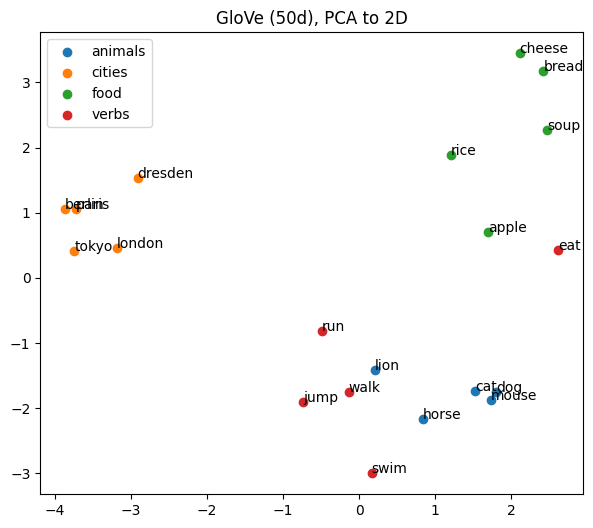

In [29]:
from sklearn.decomposition import PCA

groups = {
    "animals": ["cat", "dog", "horse", "mouse", "lion"],
    "cities": ["dresden", "berlin", "paris", "london", "tokyo"],
    "food": ["bread", "cheese", "apple", "rice", "soup"],
    "verbs": ["run", "walk", "swim", "jump", "eat"],
}
all_words = [w for ws in groups.values() for w in ws]
X2 = PCA(n_components=2).fit_transform(np.stack([glove[w] for w in all_words]))
plt.figure(figsize=(7, 6))
for name, ws in groups.items():
    idx = [all_words.index(w) for w in ws]
    plt.scatter(X2[idx, 0], X2[idx, 1], label=name)
    for i in idx:
        plt.annotate(all_words[i], X2[i])
plt.legend()
plt.title("GloVe (50d), PCA to 2D")
plt.show()

## B★ Bonus (optional): removing the gender direction

**Exercise.** Write `debias(v)` that returns `v - (v @ g) * g`. For *nurse*, *engineer*, *receptionist*, *manager*, compare the cosine with `g`, *she* and *he* before and after. Then repeat *father : doctor :: mother : ?* with debiased vectors for all three words.

*Goal:* see how much this simple fix (Bolukbasi et al., 2016) removes, and what remains.

In [30]:
def debias(v):
    return v - (v @ g) * g

for p in ["nurse", "engineer", "receptionist", "manager"]:
    v, d = glove[p], debias(glove[p])
    print(f"{p:13s} cos with g: {cosine(v, g):+.2f} -> {cosine(d, g):+.2f}   "
          f"she/he before: {cosine(v, glove['she']):.2f}/{cosine(v, glove['he']):.2f}   "
          f"after: {cosine(d, glove['she']):.2f}/{cosine(d, glove['he']):.2f}")

target = debias(glove["doctor"]) - debias(glove["father"]) + debias(glove["mother"])
print([w for w, _ in glove.similar_by_vector(target, topn=6)])

nurse         cos with g: -0.38 -> -0.00   she/he before: 0.65/0.48   after: 0.57/0.59
engineer      cos with g: +0.13 -> +0.00   she/he before: 0.41/0.49   after: 0.45/0.47
receptionist  cos with g: -0.37 -> +0.00   she/he before: 0.35/0.18   after: 0.26/0.27
manager       cos with g: +0.30 -> +0.00   she/he before: 0.44/0.60   after: 0.56/0.58
['doctor', 'patient', 'doctors', 'nurse', 'physician', 'medical']


# C. Applications

Using word vectors for two tasks: sentence similarity and sentiment classification.

| Part | Topic |
|---|---|
| C1 | Sentence similarity with averaged word vectors |
| C2 | Sentiment classification: dense vs sparse features |

## C1. Sentence similarity

**Exercise C1.1.** Write
- `preprocess(text)`: lowercase and return the words (`re.findall(r"[a-z]+(?:'[a-z]+)?", ...)`),
- `sentence_vector(text)`: the mean GloVe vector of all known words (zeros if none),
- `cosine(u, v)`: 0 if one of the vectors is zero.

*Goal:* a simple sentence embedding.

In [31]:
def preprocess(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

def sentence_vector(text):
    vecs = [glove[w] for w in preprocess(text) if w in glove]
    return np.mean(vecs, axis=0) if vecs else np.zeros(glove.vector_size)

def cosine(u, v):
    nu, nv = np.linalg.norm(u), np.linalg.norm(v)
    return float(u @ v / (nu * nv)) if nu and nv else 0.0

**Exercise C1.2.** For each query, print the 3 most similar sentences with their scores. Add your own query.

*Goal:* semantic search with averaged word vectors.

In [32]:
sentences = [
    "The tram to the main station is delayed again",
    "Our bus was late because of the snow",
    "The library opens at eight in the morning",
    "Students can borrow books until midnight",
    "The football club won the final match",
    "The team celebrated an unexpected victory",
    "Neural networks learn representations from data",
    "Language models predict the next word",
    "I baked fresh bread with my grandmother",
    "The soup needs more salt and pepper",
]
queries = ["public transport problems", "a machine learning lecture", "cooking dinner"]

sent_vecs = [sentence_vector(s) for s in sentences]
for q in queries:
    qv = sentence_vector(q)
    ranked = sorted(((cosine(qv, v), s) for v, s in zip(sent_vecs, sentences)), reverse=True)
    print(q)
    for score, s in ranked[:3]:
        print(f"   {score:.3f}  {s}")

public transport problems
   0.802  Our bus was late because of the snow
   0.793  The tram to the main station is delayed again
   0.713  Neural networks learn representations from data
a machine learning lecture
   0.789  The library opens at eight in the morning
   0.778  Language models predict the next word
   0.775  Students can borrow books until midnight
cooking dinner
   0.774  I baked fresh bread with my grandmother
   0.695  The soup needs more salt and pepper
   0.610  Students can borrow books until midnight


**Exercise C1.3.** Plot the cosine similarity matrix of the 10 sentences (`plt.imshow`).

*Goal:* see whether sentences on the same topic form blocks.

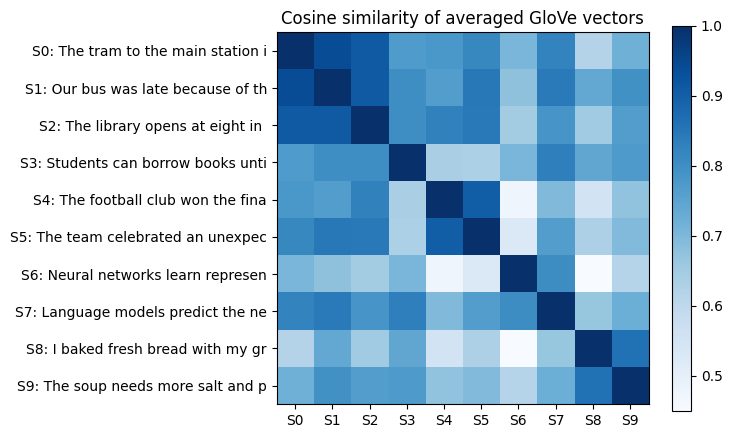

In [33]:
M = np.array([[cosine(a, b) for b in sent_vecs] for a in sent_vecs])
plt.figure(figsize=(6, 5))
plt.imshow(M, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(sentences)), [f"S{i}" for i in range(len(sentences))])
plt.yticks(range(len(sentences)), [f"S{i}: {s[:30]}" for i, s in enumerate(sentences)])
plt.title("Cosine similarity of averaged GloVe vectors")
plt.show()

**Exercise C1.4.** Compute the cosine for the pairs below.

*Goal:* find out what averaging throws away.

In [34]:
pairs = [
    ("the dog bit the man", "the man bit the dog"),
    ("the movie was good", "the movie was not good"),
    ("the movie was good", "the film was great"),
]
for a, b in pairs:
    print(f"{cosine(sentence_vector(a), sentence_vector(b)):.3f}  {a!r} vs {b!r}")

1.000  'the dog bit the man' vs 'the man bit the dog'
0.991  'the movie was good' vs 'the movie was not good'
0.967  'the movie was good' vs 'the film was great'


## C2. Sentiment classification

Rotten Tomatoes: 8,530 training and 1,066 test reviews, one sentence each, labelled positive (1) or negative (0).

In [35]:
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

data = load_dataset("cornell-movie-review-data/rotten_tomatoes")
train_texts, train_labels = data["train"]["text"], np.array(data["train"]["label"])
test_texts, test_labels = data["test"]["text"], np.array(data["test"]["label"])
print(len(train_texts), "train,", len(test_texts), "test")
print(train_texts[0], train_labels[0])

8530 train, 1066 test
the rock is destined to be the 21st century's new " conan " and that he's going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal . 1


**Exercise C2.1.** Turn every review into its averaged GloVe vector (`X_train`, `X_test`), train `LogisticRegression(max_iter=1000)` and print the test accuracy.

*Goal:* a classifier on dense features.

In [36]:
X_train = np.stack([sentence_vector(t) for t in train_texts])
X_test = np.stack([sentence_vector(t) for t in test_texts])
dense_clf = LogisticRegression(max_iter=1000).fit(X_train, train_labels)
print("GloVe average:", X_train.shape, "accuracy", round(dense_clf.score(X_test, test_labels), 3))

GloVe average: (8530, 50) accuracy 0.682


**Exercise C2.2.** Do the same with `TfidfVectorizer` (fit on the training texts only). Print the shape of the training matrix and the test accuracy.

*Goal:* compare dense with sparse features (see slides 30-36).

In [37]:
vectorizer = TfidfVectorizer()
A_train = vectorizer.fit_transform(train_texts)
A_test = vectorizer.transform(test_texts)
sparse_clf = LogisticRegression(max_iter=1000).fit(A_train, train_labels)
print("tf-idf:", A_train.shape, "accuracy", round(sparse_clf.score(A_test, test_labels), 3))

tf-idf: (8530, 16474) accuracy 0.783


**Exercise C2.3.** Train both classifiers again on only the 100 reviews in `idx` and compare the test accuracy.

*Goal:* see when dense vectors win (see slide 36).

In [38]:
idx = np.random.RandomState(0).permutation(len(train_texts))[:100]
small_texts = [train_texts[i] for i in idx]
small_labels = train_labels[idx]
dense_small = LogisticRegression(max_iter=1000).fit(X_train[idx], small_labels)
print("GloVe average, 100 examples:", round(dense_small.score(X_test, test_labels), 3))

vec_small = TfidfVectorizer()
sparse_small = LogisticRegression(max_iter=1000).fit(vec_small.fit_transform(small_texts), small_labels)
print("tf-idf, 100 examples:       ", round(sparse_small.score(vec_small.transform(test_texts), test_labels), 3))
print("words known to tf-idf:", len(vec_small.vocabulary_))

GloVe average, 100 examples: 0.619
tf-idf, 100 examples:        0.571
words known to tf-idf: 892


**Exercise C2.4.** Classify your own reviews with both full models. Try negation and sarcasm.

*Goal:* find the limits of both approaches.

In [39]:
my_reviews = [
    "I absolutely loved this movie, it was fantastic!",
    "Terrible. Waste of time.",
    "Not bad at all, actually quite enjoyable.",
    "Oh great, another two hours of my life I will never get back.",
]
for r in my_reviews:
    d = dense_clf.predict([sentence_vector(r)])[0]
    s = sparse_clf.predict(vectorizer.transform([r]))[0]
    print(f"dense: {'pos' if d else 'neg'}  tf-idf: {'pos' if s else 'neg'}  {r}")

dense: pos  tf-idf: pos  I absolutely loved this movie, it was fantastic!
dense: neg  tf-idf: neg  Terrible. Waste of time.
dense: neg  tf-idf: neg  Not bad at all, actually quite enjoyable.
dense: pos  tf-idf: neg  Oh great, another two hours of my life I will never get back.


## C★ Bonus (optional): better dense features

**Exercise.** Improve the GloVe classifier in two ways and compare the test accuracy:
1. an idf-weighted average (weights from `dict(zip(vectorizer.get_feature_names_out(), vectorizer.idf_))`, weight 1 for unknown words),
2. a plain average of `glove-wiki-gigaword-100` vectors.

*Goal:* see which helps more, and whether either beats tf-idf.

In [40]:
idf = dict(zip(vectorizer.get_feature_names_out(), vectorizer.idf_))

def weighted_vector(text):
    ws = [w for w in preprocess(text) if w in glove]
    if not ws:
        return np.zeros(glove.vector_size)
    weights = np.array([idf.get(w, 1.0) for w in ws])
    return weights @ np.stack([glove[w] for w in ws]) / weights.sum()

W_train = np.stack([weighted_vector(t) for t in train_texts])
W_test = np.stack([weighted_vector(t) for t in test_texts])
print("idf-weighted GloVe-50:", round(LogisticRegression(max_iter=1000).fit(W_train, train_labels).score(W_test, test_labels), 3))

glove100 = api.load("glove-wiki-gigaword-100")

def vector100(text):
    vecs = [glove100[w] for w in preprocess(text) if w in glove100]
    return np.mean(vecs, axis=0) if vecs else np.zeros(100)

G_train = np.stack([vector100(t) for t in train_texts])
G_test = np.stack([vector100(t) for t in test_texts])
print("plain GloVe-100:      ", round(LogisticRegression(max_iter=1000).fit(G_train, train_labels).score(G_test, test_labels), 3))

idf-weighted GloVe-50: 0.686
[==================================================] 100.0% 128.1/128.1MB downloaded
plain GloVe-100:       0.72
